# 05 · Evaluación en el conjunto de prueba (2014J)

**Pregunta.** ¿Cuánto discrimina el modelo final en un periodo que no ha intervenido en ninguna
decisión, y cuánto mejora a la regla de la nota?

**Modelo evaluado** (E11, fijado antes de abrir la prueba): regresión logística L2 con las
variables, el C y el umbral F2 del notebook 04, los mismos para los tres cortes salvo el
umbral, ajustada con 2013B, 2013J y 2014B.

**Qué se informa** (D11, D12, E10): ROC-AUC con IC del 95 % (bootstrap de estudiantes dentro de
cada clase, 1000 réplicas) del modelo y de la regla de la nota, y su diferencia pareada; curvas
ROC; matrices de confusión (modelo con su umbral F2; regla: nota media < 40) con sensibilidad,
precisión, F1 y F2 de la clase en riesgo; evolución de la alerta entre cortes consecutivos.

**Regla.** Segunda y última apertura de la prueba (E10), con `ABRIR_PRUEBA=1`. Después no se
cambia nada del modelo.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else "src")
import comun as c  # noqa: E402

import joblib  # noqa: E402
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from sklearn.metrics import confusion_matrix, f1_score, fbeta_score, precision_score, recall_score, roc_curve  # noqa: E402

c.thesis_style()
pd.set_option("display.precision", 3)
final = {cut: joblib.load(c.ARTIFACTS / f"final_{cut}.joblib") for cut in c.CUTS}
test = {cut: c.load_test(cut) for cut in c.CUTS}
assert all(set(t["code_presentation"]) == {c.TEST_PERIOD} for t in test.values())

## 1. El conjunto de prueba

In [2]:
pd.DataFrame({c.CUT_NAMES[cut]: {"filas": len(t), "asignaturas": t["code_module"].nunique(),
                                 "en riesgo (%)": 100 * t[c.TARGET].mean()} for cut, t in test.items()})

,Primer corte,Segundo corte,Tercer corte
filas,8764.000,7955.000,7603.000
asignaturas,7.000,7.000,7.000
en riesgo (%),37.734,31.402,28.226


## 2. ROC-AUC con IC del 95 %

In [3]:
pred, boot = {}, {}
for cut in c.CUTS:
    t, f = test[cut], final[cut]
    pred[cut] = f["model"].predict_proba(t[f["features"]])[:, 1]
    boot[cut] = c.bootstrap_auc(t[c.TARGET], {"modelo": pred[cut], "nota": c.baseline_score(t)},
                                c.class_id(t), reference="nota")
auc_table = pd.concat(boot, names=["corte", "puntuación"])
auc_table

auc  ic_inf  ic_sup    dif  dif_inf  dif_sup
corte puntuación                                                
first modelo      0.787   0.778   0.797  0.033    0.029    0.038
      nota        0.754   0.744   0.765  0.000    0.000    0.000
mid   modelo      0.883   0.875   0.891  0.038    0.034    0.043
      nota        0.845   0.836   0.854  0.000    0.000    0.000
last  modelo      0.923   0.917   0.930  0.024    0.020    0.028
      nota        0.899   0.892   0.907  0.000    0.000    0.000

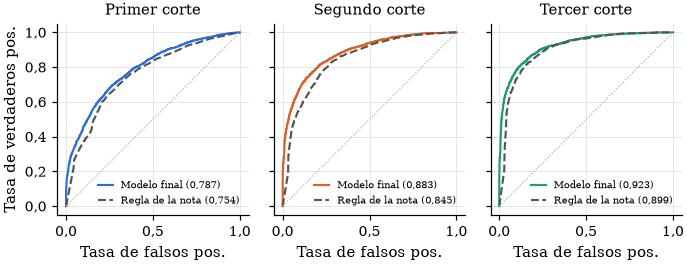

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(6.5, 2.8), sharey=True)
for ax, cut in zip(axes, c.CUTS):
    t = test[cut]
    for name, score, ls in [("Modelo final", pred[cut], "-"), ("Regla de la nota", c.baseline_score(t), "--")]:
        fpr, tpr, _ = roc_curve(t[c.TARGET], score)
        key = "modelo" if ls == "-" else "nota"
        ax.plot(fpr, tpr, ls, color=c.CUT_COLORS[cut] if ls == "-" else "#555555", lw=1.4,
                label=f"{name} ({c.comma(boot[cut].loc[key, 'auc'])})")
    ax.plot([0, 1], [0, 1], ":", color="#aaaaaa", lw=0.8)
    ax.set_title(c.CUT_NAMES[cut])
    ax.set_xlabel("Tasa de falsos pos.")
    ax.set_aspect("equal")
    ax.legend(loc="lower right", fontsize=6.5, handlelength=1.5)
    c.comma_axis(ax, "x", 1)
    c.comma_axis(ax, "y", 1)
axes[0].set_ylabel("Tasa de verdaderos pos.")
fig.tight_layout()
c.save_figure(fig, "curvas_roc_prueba")
plt.show()

## 3. Matrices de confusión y métricas de la clase en riesgo

In [5]:
labels = {cut: {"Modelo final": (pred[cut] >= final[cut]["threshold"]).astype(int), "Regla de la nota": c.baseline_label(test[cut])}
          for cut in c.CUTS}
rows = []
for cut in c.CUTS:
    y = test[cut][c.TARGET].to_numpy()
    for name, yhat in labels[cut].items():
        tn, fp, fn, tp = confusion_matrix(y, yhat).ravel()
        rows.append({"corte": cut, "clasificador": name, "VP": tp, "FN": fn, "FP": fp, "VN": tn,
                     "sensibilidad": recall_score(y, yhat), "precisión": precision_score(y, yhat),
                     "F1": f1_score(y, yhat), "F2": fbeta_score(y, yhat, beta=2),
                     "marcados (%)": 100 * yhat.mean(), "falsas alarmas (% de quienes aprueban)": 100 * fp / (fp + tn)})
cm_table = pd.DataFrame(rows).set_index(["corte", "clasificador"])
cm_table

VP    FN    FP    VN  sensibilidad  precisión  \
corte clasificador                                                        
first Modelo final      3073   234  3622  1835         0.929      0.459   
      Regla de la nota  1250  2057   589  4868         0.378      0.680   
mid   Modelo final      2232   266  1962  3495         0.894      0.532   
      Regla de la nota  1220  1278   359  5098         0.488      0.773   
last  Modelo final      1904   242  1185  4272         0.887      0.616   
      Regla de la nota  1249   897   271  5186         0.582      0.822   

                           F1     F2  marcados (%)  \
corte clasificador                                   
first Modelo final      0.614  0.771        76.392   
      Regla de la nota  0.486  0.415        20.984   
mid   Modelo final      0.667  0.787        52.722   
      Regla de la nota  0.598  0.527        19.849   
last  Modelo final      0.727  0.816        40.629   
      Regla de la nota  0.681  0.618        19.992   

                        falsas alarmas (% de quienes aprueban)  
corte clasificador                                              
first Modelo final                                      66.373  
      Regla de la nota                                  10.793  
mid   Modelo final                                      35.954  
      Regla de la nota                                   6.579  
last  Modelo final                                      21.715  
      Regla de la nota                                   4.966

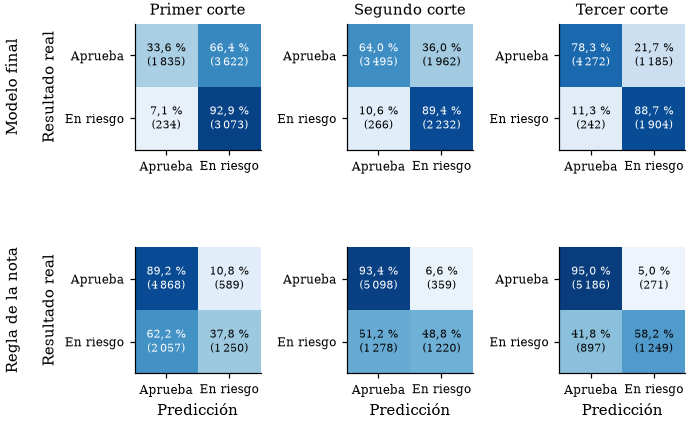

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(6.5, 4.6))
for j, cut in enumerate(c.CUTS):
    y = test[cut][c.TARGET].to_numpy()
    for i, (name, yhat) in enumerate(labels[cut].items()):
        ax = axes[i, j]
        cm = confusion_matrix(y, yhat)
        norm = cm / cm.sum(axis=1, keepdims=True)
        ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
        for a in range(2):
            for b in range(2):
                count = f"{cm[a, b]:,}".replace(",", " ")  # separador de miles sin tocar la coma decimal
                ax.text(b, a, f"{c.comma(100 * norm[a, b], 1)} %\n({count})",
                        ha="center", va="center", fontsize=7.5, color="white" if norm[a, b] > 0.6 else "black")
        ax.set_xticks([0, 1], ["Aprueba", "En riesgo"], fontsize=8)
        ax.set_yticks([0, 1], ["Aprueba", "En riesgo"], fontsize=8)
        ax.grid(False)
        if i == 0:
            ax.set_title(c.CUT_NAMES[cut])
        if i == 1:
            ax.set_xlabel("Predicción")
        if j == 0:
            ax.set_ylabel(f"{name}\n\nResultado real")
fig.tight_layout()
c.save_figure(fig, "matrices_confusion_prueba")
plt.show()

## 4. Evolución de la alerta entre cortes consecutivos

Estudiantes presentes en los dos cortes (quien se da de baja entre uno y otro ya no está en el
segundo). Para cada cambio de alerta, cuántos son y qué proporción está realmente en riesgo.

In [7]:
KEY = ["id_student", "code_module"]
GROUPS = {(0, 0): "Sin alerta en ambos", (1, 0): "Sale de riesgo", (0, 1): "Entra en riesgo", (1, 1): "En riesgo en ambos"}
trans = []
for a, b in [("first", "mid"), ("mid", "last")]:
    A = test[a][KEY].assign(alerta_a=labels[a]["Modelo final"])
    B = test[b][KEY + [c.TARGET]].assign(alerta_b=labels[b]["Modelo final"])
    m = A.merge(B, on=KEY)
    for (ga, gb), g in m.groupby(["alerta_a", "alerta_b"]):
        trans.append({"paso": f"{a}→{b}", "grupo": GROUPS[ga, gb], "estudiantes": len(g),
                      "% del paso": 100 * len(g) / len(m), "en riesgo real (%)": 100 * g[c.TARGET].mean()})
trans = pd.DataFrame(trans)
trans

,paso,grupo,estudiantes,% del paso,en riesgo real (%)
0,first→mid,Sin alerta en ambos,1810,22.753,4.475
1,first→mid,Entra en riesgo,189,2.376,43.915
2,first→mid,Sale de riesgo,1951,24.525,9.482
3,first→mid,En riesgo en ambos,4005,50.346,53.658
4,mid→last,Sin alerta en ambos,3433,45.153,3.379
5,mid→last,Entra en riesgo,267,3.512,33.333
6,mid→last,Sale de riesgo,1081,14.218,11.656
7,mid→last,En riesgo en ambos,2822,37.117,64.316


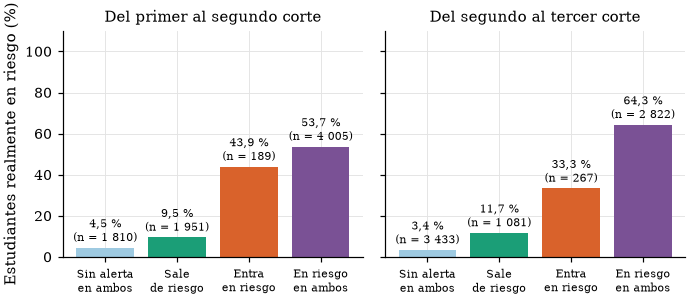

In [8]:
order_g = list(GROUPS.values())
fig, axes = plt.subplots(1, 2, figsize=(6.5, 2.9), sharey=True)
for ax, (step, title) in zip(axes, [("first→mid", "Del primer al segundo corte"), ("mid→last", "Del segundo al tercer corte")]):
    t = trans[trans["paso"] == step].set_index("grupo").reindex(order_g)
    colors = ["#9ecae1", "#1b9e77", "#d9622b", "#7a5195"]
    ax.bar(range(4), t["en riesgo real (%)"], color=colors)
    for i, (pct, n) in enumerate(zip(t["en riesgo real (%)"], t["estudiantes"])):
        count = f"{n:,}".replace(",", " ")  # separador de miles sin tocar la coma decimal
        ax.text(i, pct + 1.5, f"{c.comma(pct, 1)} %\n(n = {count})", ha="center", va="bottom", fontsize=7)
    ax.set_xticks(range(4), ["Sin alerta\nen ambos", "Sale\nde riesgo", "Entra\nen riesgo", "En riesgo\nen ambos"], fontsize=7.5)
    ax.set_title(title)
    ax.set_ylim(0, 110)
axes[0].set_ylabel("Estudiantes realmente en riesgo (%)")
fig.tight_layout()
c.save_figure(fig, "evolucion_alertas_prueba")
plt.show()

In [9]:
c.save_json({"auc": auc_table.reset_index().to_dict("records"), "cm": cm_table.reset_index().to_dict("records"),
             "transiciones": trans.to_dict("records")}, c.ARTIFACTS / "05_prueba.json")

## Conclusiones

- **ROC-AUC en 2014J**: 0,787 · 0,883 · 0,923 (IC ±0,008 aprox.). Supera a la regla de la nota
  por 0,033 · 0,038 · 0,024, con IC por encima de 0.
- **Umbral F2**: detecta al 93 % · 89 % · 89 % de los estudiantes en riesgo (la regla, al 38 % ·
  49 % · 58 %), con precisión 0,46 · 0,53 · 0,62. El precio son las falsas alarmas: reciben alerta
  el 66 % · 36 % · 22 % de quienes aprueban, y se marca al 76 % · 53 % · 41 % de la clase. Es la
  prioridad fijada (captar a casi todos; la lista se ordena después por probabilidad).
- **Evolución entre cortes**: quien sale de la alerta está realmente en riesgo en un 9–12 %
  (casi como quien nunca la tuvo, 3–4 %); quien entra, en un 33–44 %; quien sigue, en un
  54–64 %. La alerta del corte siguiente corrige a la del anterior.
- Segunda y última apertura de la prueba (E10, E15). No se cambia nada del modelo.